<a href="https://colab.research.google.com/github/ScrubOverlord/Emmanuel_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('car_purchase_data.csv')
print('Shape:', df.shape)
display(df.head())
df.info()
print(df.isna().sum())
print(df['Purchased'].value_counts())

Shape: (400, 5)


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   User ID    400 non-null    int64 
 1   Gender     400 non-null    object
 2   Age        400 non-null    int64 
 3   Salary     400 non-null    int64 
 4   Purchased  400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64
Purchased
0    257
1    143
Name: count, dtype: int64


### Step 2: Split features and target

In [11]:
X = df[['Age', 'Salary']]
y = df['Purchased']
print(X.shape, y.shape)

(400, 2) (400,)


### Step 3: Train/Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(X_train.shape[0], X_test.shape[0])

300 100


### Step 4: Feature Scaling

In [13]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Step 5: Train Logistic Regression Model

In [14]:
model = LogisticRegression(random_state=0)
model.fit(X_train_s, y_train)
print('Coefficients (Age, Salary):', model.coef_[0].round(3))
print('Intercept:', model.intercept_.round(3))

Coefficients (Age, Salary): [2.077 1.11 ]
Intercept: [-0.952]


### Step 6: Predict and Evaluate

Test Accuracy: 0.8900 (89.0%)
Meets 87.5% requirement: True
[[65  3]
 [ 8 24]]
              precision    recall  f1-score   support

           0       0.89      0.96      0.92        68
           1       0.89      0.75      0.81        32

    accuracy                           0.89       100
   macro avg       0.89      0.85      0.87       100
weighted avg       0.89      0.89      0.89       100



,P(Purchased=1),Predicted (p>=0.5),Actual
0,0.113,0,0
1,0.167,0,0
2,0.195,0,0
3,0.089,0,0
4,0.097,0,0
5,0.008,0,0
6,0.015,0,0
7,0.732,1,1


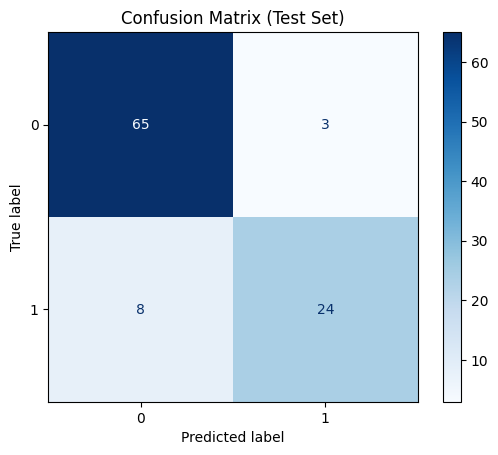

In [15]:
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]
acc = accuracy_score(y_test, y_pred)
print(f'Test Accuracy: {acc:.4f} ({acc*100:.1f}%)')
print('Meets 87.5% requirement:', acc >= 0.875)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
display(pd.DataFrame({'P(Purchased=1)': y_prob[:8].round(3),
                      'Predicted (p>=0.5)': y_pred[:8],
                      'Actual': y_test.values[:8]}))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()

### Step 7: Visualization of Decision Regions

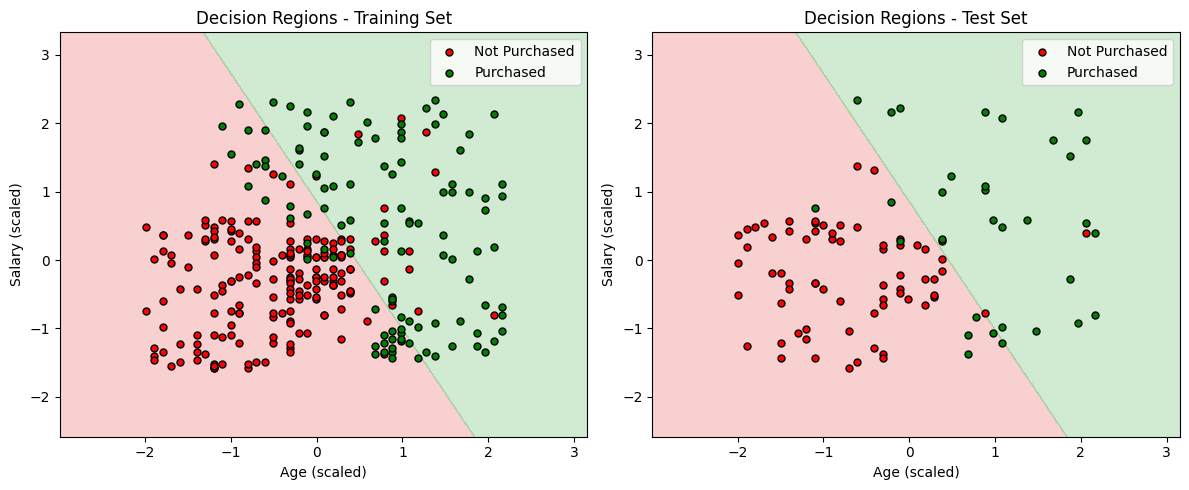

In [16]:
def plot_regions(Xs, ys, title):
    x1, x2 = np.meshgrid(
        np.arange(Xs[:,0].min()-1, Xs[:,0].max()+1, 0.01),
        np.arange(Xs[:,1].min()-1, Xs[:,1].max()+1, 0.01))
    Z = model.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
    plt.contourf(x1, x2, Z, alpha=0.5, cmap=ListedColormap(['#f4a3a3', '#a3d9a5']))
    for cls, col, lab in [(0,'red','Not Purchased'),(1,'green','Purchased')]:
        plt.scatter(Xs[ys==cls,0], Xs[ys==cls,1], c=col, edgecolor='k', s=25, label=lab)
    plt.title(title); plt.xlabel('Age (scaled)'); plt.ylabel('Salary (scaled)'); plt.legend()

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plot_regions(X_train_s, y_train.values, 'Decision Regions - Training Set')
plt.subplot(1,2,2); plot_regions(X_test_s, y_test.values, 'Decision Regions - Test Set')
plt.tight_layout(); plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1.
Logistic regression applies a linear decision score into a "sigmoid function" which transforms it into a probability P(y=1 | x) between 0 and 1. This is passed into a threshold (by default 0.5) that converts the probability into a class: "Purchased" if above 0.5, otherwise "Not Purchased". Because the sigmoid is exactly 0.5 when the score is 0, this is equivalent to drawing a linear boundary (a straight line) between the two classes. Any threshold can be used: lowering it increases recall (number of buyers found) at the cost of new false positives; raising it had the opposite effect. The probabilities also give an indication of the model's confidence.

2.
Coefficients are positive (Age 2.08, Salary 1.11 on the scaled features), so the probability of purchase increases with age and salary. The customers most likely to purchase the product are those on the upper right of the decision plot, in the green region with high age and high salary. Conversely, the customers least likely to purchase have low age and low salary. Age has a larger coefficient and appears to be more important predictor of the two.

3.  
Accuracy may be worse due to the limitations of the model, such as it only being able to use two features (excluding anything inbetween the features that are used) and the fact that it only takes a straight decision boundary and it misclassifies some points in the middle (where the true boundary is curved). The imbalance in classes (36% buyers) makes the model lean towards "No" which explains why most false negatives. Accuracy was volatile over 100 rows in the test set (values between 83-89%) so small test set size affects accuracy and the empty part of the matrix shows wrong labels, outliers or features which have not been scaled could also reduce accuracy.

4.  
One possible way to improve accuracy is to create more informative features such as Gender (one hot), occupation, credit score, current cars owned, or number of people in the family. (Feature engineering-an Age×Salary interaction, polynomial terms, or log(Salary)-can also help capture a curved boundary.) For preprocessing and hyperparameter tuning, I would continue to standardize the features, use class_weight='balanced' or tune the decision threshold to account for the class imbalance, and use GridSearchCV with stratified cross-validation to tune the regularization strength C and get a more representative accuracy estimate than a single train/test split. It would also be interesting to compare to non-linear models such as an SVM with an RBF kernel or a random forest, and to gather more data if possible.